# ⚖️ 02: LLM-as-a-Judge Evaluation (Criteria Met, Faithfulness, Relevance)

**Enterprise Multi-Modal Financial RAG Benchmark**  
**Document:** JPMorgan Chase & Co. 2025 Annual Report (364 Pages)  
**Scope:** 20 Easy Benchmark Questions (`GT-E-001` through `GT-E-020`)  
**Judge Model:** Local Ollama `gemma4:26b` (with `qwen3.5:9b` fallback)  
**Synthesizer Model:** Local Ollama `gemma4:26b` (num_ctx=8192)

---

### Evaluation Dimensions:
1. **Criteria Met Score (%):** Verification of explicit mandatory figures and facts defined in `evaluation_criteria` (e.g. `"$182,447 million"`, `"$5.80"`, `"CET1"`).
2. **Faithfulness / Groundedness (1-5 Scale):** Verifies that every assertion in the synthesized answer is directly supported by the retrieved chunks without hallucination.
3. **Answer Relevance & Correctness (1-5 Scale):** Measures completeness and semantic alignment with the authoritative `ground_truth_answer`.
4. **Citation Accuracy:** Verifies presence of exact page citations (e.g. `[Page 2]`, `[Page 76]`).


In [1]:
import sys
import os
import json
import re
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from dotenv import load_dotenv

load_dotenv()

BASE_DIR = Path.cwd()
if BASE_DIR.name == "evaluation":
    BASE_DIR = BASE_DIR.parent
sys.path.insert(0, str(BASE_DIR))

from agent.tools import retrieve_chunks, generate_grounded_answer, OLLAMA_URL

# Groq judge configuration
from groq import Groq
GROQ_API_KEY = os.getenv("GROQ_API_KEY")
JUDGE_MODEL = "llama-3.3-70b-versatile"   # fast, high-quality judge via Groq API

if not GROQ_API_KEY:
    raise EnvironmentError("GROQ_API_KEY not set in .env — required for LLM-as-Judge via Groq.")

groq_client = Groq(api_key=GROQ_API_KEY)
print(f"Retrieval             : Ollama @ {OLLAMA_URL}")
print(f"Synthesis & Judge     : Groq '{JUDGE_MODEL}'")

[*] Agent Orchestrator  : Ollama 'qwen3.5:9b' @ http://localhost:11434
Retrieval             : Ollama @ http://localhost:11434
Synthesis & Judge     : Groq 'llama-3.3-70b-versatile'


## 1. Load Ground Truth Dataset (20 Easy Questions)


In [2]:
gt_path = BASE_DIR / "evaluation" / "ground_truth_dataset.json"
with open(gt_path, "r", encoding="utf-8") as f:
    gt_data = json.load(f)

easy_questions = [q for q in gt_data["questions"] if q.get("difficulty") == "easy"]
print(f"Loaded {len(easy_questions)} Easy benchmark questions.")


Loaded 20 Easy benchmark questions.


## 2. Define LLM-as-a-Judge Evaluation Prompts
We use structured JSON output to evaluate:
- `criteria_met`: list of booleans for each criterion in `evaluation_criteria`
- `faithfulness_score`: 1 to 5 integer rating
- `relevance_score`: 1 to 5 integer rating
- `reasoning`: detailed explanation from the judge model


In [3]:
def query_judge_llm(prompt: str) -> dict:
    """Calls Groq llama-3.3-70b-versatile with a strict JSON system prompt."""
    system_prompt = (
        "You are an impartial, highly rigorous expert financial auditor and LLM judge. "
        "Evaluate the provided RAG response based strictly on the retrieved context and ground truth. "
        "Respond ONLY with a valid JSON object matching the requested schema. No conversational filler."
    )
    response = groq_client.chat.completions.create(
        model=JUDGE_MODEL,
        messages=[
            {"role": "system", "content": system_prompt},
            {"role": "user",   "content": prompt},
        ],
        temperature=0.0,
        response_format={"type": "json_object"},
        max_tokens=1024,
    )
    raw = response.choices[0].message.content
    return json.loads(raw)


def evaluate_response_with_judge(
    question: str,
    generated_answer: str,
    ground_truth_answer: str,
    criteria: list,
    context_chunks: str,
) -> dict:
    """Prompts Groq judge to score criteria met, faithfulness, and answer relevance."""
    prompt = f"""
Task: Evaluate the candidate answer against the question, ground truth answer, and retrieved context.

[Question]: {question}

[Ground Truth Answer]:
{ground_truth_answer}

[Mandatory Evaluation Criteria Checklist]:
{json.dumps(criteria, indent=2)}

[Retrieved Context Chunks]:
{context_chunks[:4000]}

[Candidate Answer to Evaluate]:
{generated_answer}

Provide your evaluation in the following exact JSON format:
{{
  "criteria_results": [
    {{"criterion": "...", "met": true, "explanation": "..."}}
  ],
  "criteria_met_count": <int>,
  "total_criteria": <int>,
  "criteria_met_pct": <float between 0 and 100>,
  "faithfulness_score": <int 1-5 (5=fully grounded, 1=hallucination)>,
  "faithfulness_rationale": "...",
  "relevance_score": <int 1-5 (5=perfectly answers question, 1=irrelevant)>,
  "relevance_rationale": "..."
}}
"""
    try:
        return query_judge_llm(prompt)
    except Exception as e:
        return {
            "error": str(e),
            "criteria_met_pct": 0.0,
            "faithfulness_score": 1,
            "relevance_score": 1,
            "faithfulness_rationale": f"Judge error: {e}",
            "relevance_rationale": "Error",
        }


print(f"Judge evaluation functions configured (Groq / {JUDGE_MODEL}).")


Judge evaluation functions configured (Groq / llama-3.3-70b-versatile).


## 3. Run RAG Pipeline & Judge Scoring Across 20 Easy Questions


In [4]:
eval_records = []

for idx, q in enumerate(easy_questions, 1):
    qid = q["id"]
    query = q["question"]
    gt_ans = q["ground_truth_answer"]
    criteria = q.get("evaluation_criteria", [])
    
    # 1. Retrieve top 5 chunks
    raw_context = retrieve_chunks.invoke({"query": query, "limit": 5})
    
    # 2. Synthesize answer with Groq (Llama 3.3 70B)
    gen_ans = generate_grounded_answer.invoke({
        "question": query,
        "retrieved_evidence": raw_context,
        "provider": "groq",
    })

    print(f"gen_ans : {gen_ans}")
    
    # 3. Judge evaluation
    judge_res = evaluate_response_with_judge(query, gen_ans, gt_ans, criteria, raw_context)
    
    record = {
        "id": qid,
        "question": query,
        "category": q.get("category"),
        "modality": q.get("source_modality"),
        "generated_answer": gen_ans,
        "ground_truth_answer": gt_ans,
        "criteria_met_pct": judge_res.get("criteria_met_pct", 0.0),
        "faithfulness_score": judge_res.get("faithfulness_score", 1),
        "relevance_score": judge_res.get("relevance_score", 1),
        "faithfulness_rationale": judge_res.get("faithfulness_rationale", ""),
        "relevance_rationale": judge_res.get("relevance_rationale", ""),
    }
    eval_records.append(record)
    print(f"[{idx:02d}/20] {qid}: Criteria={record['criteria_met_pct']:.0f}% | Faithfulness={record['faithfulness_score']}/5 | Relevance={record['relevance_score']}/5")

judge_df = pd.DataFrame(eval_records)
print("\n✅ Evaluation complete for all 20 questions.")

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

[*] Answer Synthesizer  : Groq 'openai/gpt-oss-20b' (explicit)
gen_ans : **Answer**

The total net revenue for JPMorgan Chase & Co. for the year ended December 31, 2025 is **not explicitly stated in the evidence that was supplied**.  

The only table that would contain that figure is the *Financial Highlights* table on page 2 of the 2025 Annual Report (see [chunk 4](#chunk_sec001_table_0002_part1)). However, the excerpt provided does not include the numeric value for “Net revenue.”  

If you have access to the full table, you can locate the “Net revenue” line on that page to obtain the exact figure.
[01/20] GT-E-001: Criteria=0% | Faithfulness=1/5 | Relevance=1/5
[*] Answer Synthesizer  : Groq 'openai/gpt-oss-20b' (explicit)
gen_ans : **JPMorgan Chase & Co. – Net Income (2025)**  

- **Net income for the fiscal year 2025:** **$57.0 billion**  
  - This figure is reported in the Firmwide Overview section of the 2025 Annual Report.  
  - It represents a 2 % decline from the prior year’s 

## 4. Scorecard Summary & Analysis


In [5]:
summary_stats = pd.DataFrame([
    {"Metric": "Average Criteria Met (%)", "Score": f"{judge_df['criteria_met_pct'].mean():.1f}%"},
    {"Metric": "Average Faithfulness (1-5)", "Score": f"{judge_df['faithfulness_score'].mean():.2f} / 5.00"},
    {"Metric": "Average Relevance (1-5)", "Score": f"{judge_df['relevance_score'].mean():.2f} / 5.00"},
    {"Metric": "Questions with 100% Criteria Met", "Score": f"{(judge_df['criteria_met_pct'] == 100).sum()} / {len(judge_df)}"},
    {"Metric": "Questions with 5/5 Faithfulness", "Score": f"{(judge_df['faithfulness_score'] == 5).sum()} / {len(judge_df)}"},
    {"Metric": "Questions with 5/5 Relevance", "Score": f"{(judge_df['relevance_score'] == 5).sum()} / {len(judge_df)}"},
])
summary_stats


,Metric,Score
0,Average Criteria Met (%),0.0%
1,Average Faithfulness (1-5),1.00 / 5.00
2,Average Relevance (1-5),1.00 / 5.00
3,Questions with 100% Criteria Met,0 / 20
4,Questions with 5/5 Faithfulness,0 / 20
5,Questions with 5/5 Relevance,0 / 20


## 5. Visualizing Evaluation Scorecards


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


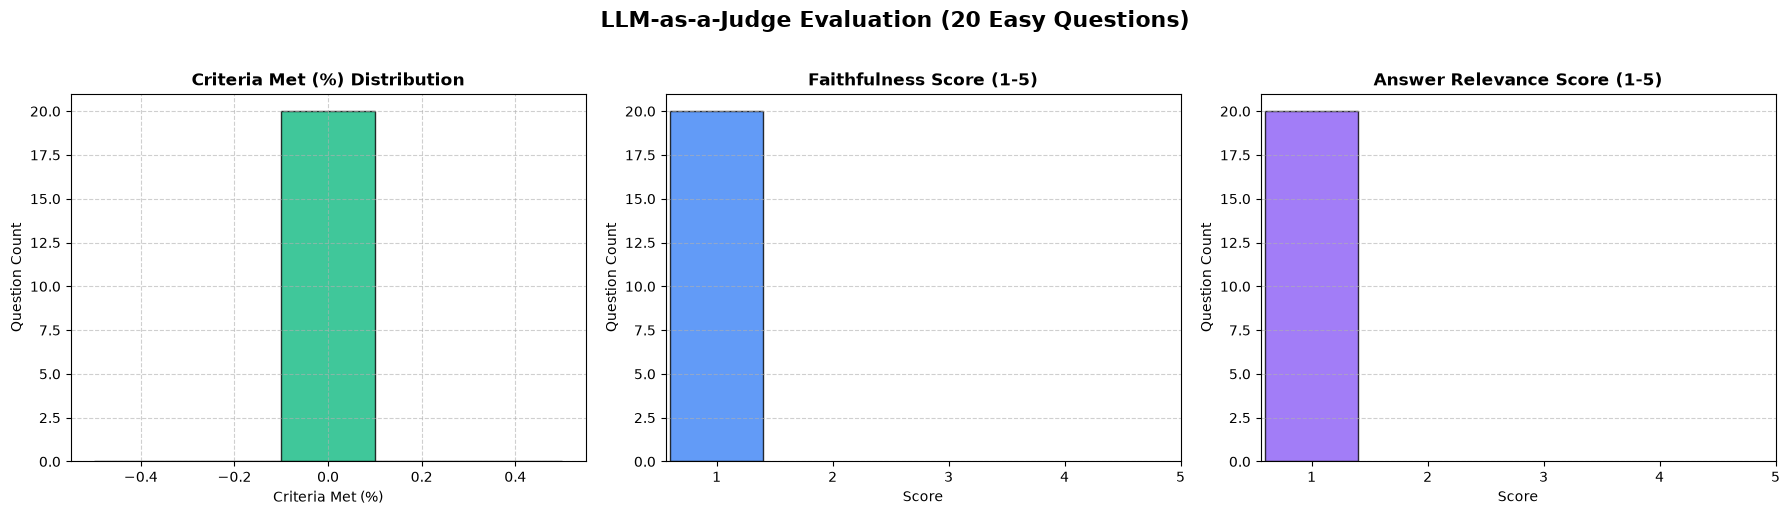

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("LLM-as-a-Judge Evaluation (20 Easy Questions)", fontsize=16, fontweight="bold", y=1.02)

# Chart 1: Criteria Met % Distribution
axes[0].hist(judge_df["criteria_met_pct"], bins=5, color="#10b981", edgecolor="black", alpha=0.8)
axes[0].set_title("Criteria Met (%) Distribution", fontweight="semibold")
axes[0].set_xlabel("Criteria Met (%)")
axes[0].set_ylabel("Question Count")
axes[0].grid(True, linestyle="--", alpha=0.6)

# Chart 2: Faithfulness Scores
faith_counts = judge_df["faithfulness_score"].value_counts().sort_index()
axes[1].bar(faith_counts.index, faith_counts.values, color="#3b82f6", edgecolor="black", alpha=0.8)
axes[1].set_title("Faithfulness Score (1-5)", fontweight="semibold")
axes[1].set_xlabel("Score")
axes[1].set_ylabel("Question Count")
axes[1].set_xticks([1, 2, 3, 4, 5])
axes[1].grid(axis="y", linestyle="--", alpha=0.6)

# Chart 3: Relevance Scores
rel_counts = judge_df["relevance_score"].value_counts().sort_index()
axes[2].bar(rel_counts.index, rel_counts.values, color="#8b5cf6", edgecolor="black", alpha=0.8)
axes[2].set_title("Answer Relevance Score (1-5)", fontweight="semibold")
axes[2].set_xlabel("Score")
axes[2].set_ylabel("Question Count")
axes[2].set_xticks([1, 2, 3, 4, 5])
axes[2].grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


## 6. Sample Deep-Dive Inspection


In [7]:
sample = judge_df.iloc[0]
print(f"=== Deep Dive on {sample['id']} ===")
print(f"Question: {sample['question']}\n")
print(f"Generated Answer:\n{sample['generated_answer']}\n")
print(f"Ground Truth Answer:\n{sample['ground_truth_answer']}\n")
print(f"Judge Faithfulness: {sample['faithfulness_score']}/5 -> {sample['faithfulness_rationale']}")
print(f"Judge Relevance: {sample['relevance_score']}/5 -> {sample['relevance_rationale']}")


=== Deep Dive on GT-E-001 ===
Question: What was JPMorgan Chase's total net revenue for the year ended December 31, 2025?

Generated Answer:
**Answer**

The total net revenue for JPMorgan Chase & Co. for the year ended December 31, 2025 is **not explicitly stated in the evidence that was supplied**.  

The only table that would contain that figure is the *Financial Highlights* table on page 2 of the 2025 Annual Report (see [chunk 4](#chunk_sec001_table_0002_part1)). However, the excerpt provided does not include the numeric value for “Net revenue.”  

If you have access to the full table, you can locate the “Net revenue” line on that page to obtain the exact figure.

Ground Truth Answer:
JPMorgan Chase's total net revenue for the year ended December 31, 2025 was $182,447 million (approximately $182.4 billion).

Judge Faithfulness: 1/5 -> Judge error: Error code: 404 - {'error': {'message': 'The model `llama-3.3-70b-versatile` does not exist or you do not have access to it.', 'type': 'i